<a href="https://colab.research.google.com/github/samritha07/Deep-Learning/blob/main/EX7_SAMRITHA_S_24BAD103.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Name: SAMRITHA S | Roll No: 24BAD103
print("Name: SAMRITHA S | Roll No: 24BAD103")
print("-" * 60)

import sys, subprocess, importlib

# Install any missing library (Google Colab normally already has these)
for pkg in ["nltk", "gensim", "numpy", "matplotlib"]:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import string
import numpy as np
import matplotlib.pyplot as plt
import nltk

# Download all required NLTK resources (unknown ids are simply skipped on older versions)
for res in ["brown", "punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(res, quiet=True)

print("NLTK version  :", nltk.__version__)
import gensim
print("Gensim version:", gensim.__version__)
print("NumPy version :", np.__version__)
print("Setup completed successfully.")


Name: SAMRITHA S | Roll No: 24BAD103
------------------------------------------------------------
NLTK version  : 3.9.1
Gensim version: 4.4.0
NumPy version : 2.1.3
Setup completed successfully.


In [2]:
# Name: SAMRITHA S | Roll No: 24BAD103
print("Name: SAMRITHA S | Roll No: 24BAD103")
print("-" * 60)

from nltk.corpus import brown, stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# 1. Load the Brown Corpus and select the "news" category
category = "news"
print("Available categories:", brown.categories())
print("Selected category   :", category)

# Brown already stores tokens; join them back into raw sentence strings
raw_sentences = [" ".join(sent) for sent in brown.sents(categories=category)]
print("Total sentences in category:", len(raw_sentences))

# 2. Examine sample sentences
print("\nSample sentences from the dataset:")
for i in range(3):
    print(f"  [{i+1}] {raw_sentences[i]}")


Name: SAMRITHA S | Roll No: 24BAD103
------------------------------------------------------------
Available categories: ['adventure', 'belles_lettres', 'editorial', 'fiction', 'government', 'hobbies', 'humor', 'learned', 'lore', 'mystery', 'news', 'religion', 'reviews', 'romance', 'science_fiction']
Selected category   : news
Total sentences in category: 4623

Sample sentences from the dataset:
  [1] The Fulton County Grand Jury said Friday an investigation of Atlanta's recent primary election produced `` no evidence '' that any irregularities took place .
  [2] The jury further said in term-end presentments that the City Executive Committee , which had over-all charge of the election , `` deserves the praise and thanks of the City of Atlanta '' for the manner in which the election was conducted .
  [3] The September-October term jury had been charged by Fulton Superior Court Judge Durwood Pye to investigate reports of possible `` irregularities '' in the hard-fought primary which was 

In [3]:
# Name: SAMRITHA S | Roll No: 24BAD103
print("Name: SAMRITHA S | Roll No: 24BAD103")
print("-" * 60)

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    """Lowercase -> tokenize -> remove punctuation -> remove stop words -> lemmatize."""
    text = text.lower()                                          # lowercase
    tokens = word_tokenize(text)                                 # NLTK word tokenization
    tokens = [t for t in tokens if t not in string.punctuation]  # remove punctuation tokens
    tokens = [t for t in tokens if t.isalpha()]                  # drop numbers / `` '' etc.
    tokens = [t for t in tokens if t not in stop_words]          # remove stop words
    tokens = [lemmatizer.lemmatize(t) for t in tokens]           # lemmatization
    return tokens

# Step-by-step demonstration on one sentence
sample = raw_sentences[1]
print("Original sentence :", sample)
lower = sample.lower()
print("1) Lowercase      :", lower)
tok = word_tokenize(lower)
print("2) Tokenized      :", tok)
no_punct = [t for t in tok if t not in string.punctuation and t.isalpha()]
print("3) No punctuation :", no_punct)
no_stop = [t for t in no_punct if t not in stop_words]
print("4) No stop words  :", no_stop)
lemmas = [lemmatizer.lemmatize(t) for t in no_stop]
print("5) Lemmatized     :", lemmas)

# Apply to the whole category (keep only non-empty sentences)
processed_sentences = []
for s in raw_sentences:
    p = preprocess(s)
    if p:
        processed_sentences.append(p)

print("\nSentences after preprocessing:", len(processed_sentences))
print("\nOriginal vs Preprocessed (first 3 sentences):")
for i in range(3):
    print(f"\nOriginal     : {raw_sentences[i]}")
    print(f"Preprocessed : {processed_sentences[i]}")


Name: SAMRITHA S | Roll No: 24BAD103
------------------------------------------------------------
Original sentence : The jury further said in term-end presentments that the City Executive Committee , which had over-all charge of the election , `` deserves the praise and thanks of the City of Atlanta '' for the manner in which the election was conducted .
1) Lowercase      : the jury further said in term-end presentments that the city executive committee , which had over-all charge of the election , `` deserves the praise and thanks of the city of atlanta '' for the manner in which the election was conducted .
2) Tokenized      : ['the', 'jury', 'further', 'said', 'in', 'term-end', 'presentments', 'that', 'the', 'city', 'executive', 'committee', ',', 'which', 'had', 'over-all', 'charge', 'of', 'the', 'election', ',', '``', 'deserves', 'the', 'praise', 'and', 'thanks', 'of', 'the', 'city', 'of', 'atlanta', '``', 'for', 'the', 'manner', 'in', 'which', 'the', 'election', 'was', 'conducted

Name: SAMRITHA S | Roll No: 24BAD103
------------------------------------------------------------
Total tokens (after preprocessing): 47682
Vocabulary size                    : 9896
First 20 vocabulary words          : ['aaron', 'abandoned', 'abandonment', 'abatuno', 'abbey', 'abe', 'abel', 'abell', 'abide', 'ability', 'ablaze', 'able', 'abner', 'aboard', 'abolish', 'abolition', 'abortive', 'abra', 'abraham', 'abroad']

Top 10 most frequent words:
Rank  Word           Frequency 
1     said           406       
2     year           260       
3     would          249       
4     new            241       
5     state          223       
6     one            222       
7     last           177       
8     two            174       
9     first          158       
10    president      155       


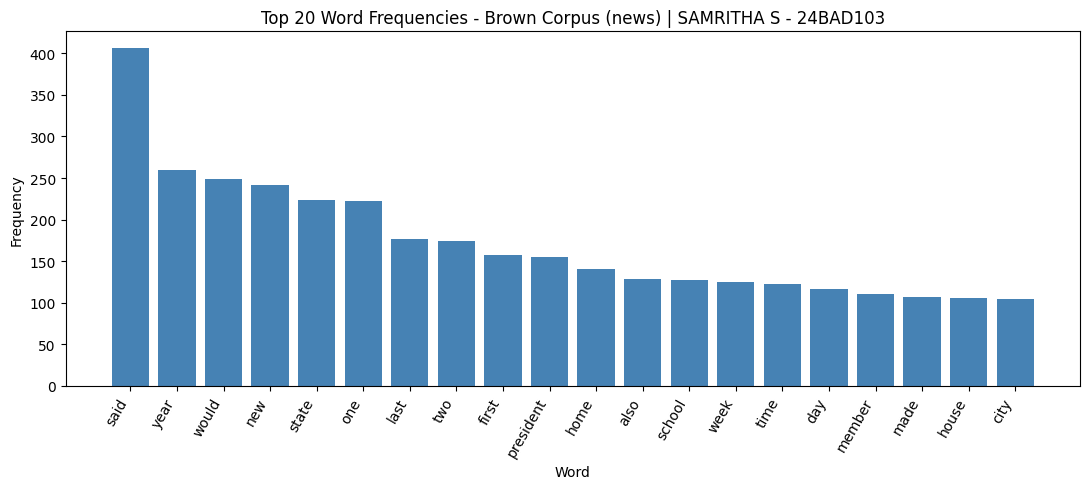


Number of tokenized sentences ready for Word2Vec: 4590
Example tokenized sentence: ['fulton', 'county', 'grand', 'jury', 'said', 'friday', 'investigation', 'atlanta', 'recent', 'primary', 'election', 'produced', 'evidence', 'irregularity', 'took', 'place']


In [4]:
# Name: SAMRITHA S | Roll No: 24BAD103
print("Name: SAMRITHA S | Roll No: 24BAD103")
print("-" * 60)

from nltk import FreqDist

# All tokens from the preprocessed text
all_tokens = [tok for sent in processed_sentences for tok in sent]

# 1. Vocabulary
vocabulary = sorted(set(all_tokens))
print("Total tokens (after preprocessing):", len(all_tokens))
print("Vocabulary size                    :", len(vocabulary))
print("First 20 vocabulary words          :", vocabulary[:20])

# 2. Frequency distribution
fdist = FreqDist(all_tokens)

# 3. Ten most frequent words
print("\nTop 10 most frequent words:")
print(f"{'Rank':<6}{'Word':<15}{'Frequency':<10}")
for rank, (word, freq) in enumerate(fdist.most_common(10), start=1):
    print(f"{rank:<6}{word:<15}{freq:<10}")

# 4. Frequency distribution plot (top 20 words)
top20 = fdist.most_common(20)
words, freqs = zip(*top20)
plt.figure(figsize=(11, 5))
plt.bar(words, freqs, color="steelblue")
plt.xticks(rotation=60, ha="right")
plt.title("Top 20 Word Frequencies - Brown Corpus (news) | SAMRITHA S - 24BAD103")
plt.xlabel("Word")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# 5. Tokenized sentences prepared for Word2Vec
sentences_for_w2v = processed_sentences
print("\nNumber of tokenized sentences ready for Word2Vec:", len(sentences_for_w2v))
print("Example tokenized sentence:", sentences_for_w2v[0])


In [5]:
# Name: SAMRITHA S | Roll No: 24BAD103
print("Name: SAMRITHA S | Roll No: 24BAD103")
print("-" * 60)

from gensim.models import Word2Vec

# Skip-gram (sg=1), 100 dimensions, window = 5
w2v_model = Word2Vec(
    sentences=sentences_for_w2v,
    vector_size=100,   # embedding dimension
    window=5,          # context-window size
    min_count=2,       # ignore words that appear only once
    sg=1,              # 1 = Skip-gram, 0 = CBOW
    workers=1,         # single worker => reproducible results
    epochs=20,
    seed=42
)

print("Word2Vec model trained successfully.")
print("Vocabulary size in Word2Vec model:", len(w2v_model.wv.key_to_index))
print("Embedding dimension              :", w2v_model.vector_size)
print("Context window                   :", w2v_model.window)
print("Architecture                     :", "Skip-gram" if w2v_model.sg == 1 else "CBOW")


Name: SAMRITHA S | Roll No: 24BAD103
------------------------------------------------------------
Word2Vec model trained successfully.
Vocabulary size in Word2Vec model: 5164
Embedding dimension              : 100
Context window                   : 5
Architecture                     : Skip-gram


In [6]:
# Name: SAMRITHA S | Roll No: 24BAD103
print("Name: SAMRITHA S | Roll No: 24BAD103")
print("-" * 60)

# Choose a selected word (preferred: "president"; otherwise the most frequent word in the model)
preferred = ["president", "state", "year", "house", "city"]
selected_word = next((w for w in preferred if w in w2v_model.wv.key_to_index),
                     w2v_model.wv.index_to_key[0])
print("Selected word:", selected_word)

# Embedding vector and its dimensions
vector = w2v_model.wv[selected_word]
print("\nEmbedding vector of '{}':".format(selected_word))
print(vector)
print("\nVector shape     :", vector.shape)
print("Vector dimension :", vector.shape[0])

# Embeddings for several other selected words
print("\nFirst 8 values of embeddings for other words:")
for w in w2v_model.wv.index_to_key[:5]:
    print(f"  {w:<12}", np.round(w2v_model.wv[w][:8], 4))

# Five most similar words
print(f"\nFive most similar words to '{selected_word}':")
for word, score in w2v_model.wv.most_similar(selected_word, topn=5):
    print(f"  {word:<15} similarity = {score:.4f}")


Name: SAMRITHA S | Roll No: 24BAD103
------------------------------------------------------------
Selected word: president

Embedding vector of 'president':
[-0.46862677 -0.34687892  0.03179901  0.55034655  0.09511758  0.10706135
  0.19001865 -0.11513062  0.04622346 -0.81460273  0.06641307 -0.12433771
  0.418521    0.6134883  -0.54983807 -0.0619005   0.20634198  0.47060484
 -0.5918648   0.55114776  0.22190705  0.70620847  0.31865    -0.0307857
 -0.06375659  0.48365194  0.13300171  0.6537125  -0.30234736 -0.24625866
  0.12025029  0.29717663 -0.12499672  0.07632045  0.5736875   0.78230625
  0.06206762 -0.29745036 -0.01643673  0.23318715  0.3602136  -0.02973006
  0.2402505  -0.13556376 -0.04162902  0.03041825  0.8489987  -0.34291106
  0.5194542  -0.8888618  -0.32938674 -0.2273067   0.21481404 -0.24398638
  0.00191743  0.47794917 -0.23487262  0.25037372  0.05995601  0.16742569
 -0.01928869 -0.3339849   0.36119872 -0.11035186  0.25993705  0.11279844
  0.2308689  -0.4466032  -0.19497475 -0.6

Name: SAMRITHA S | Roll No: 24BAD103
------------------------------------------------------------
Word 1        Word 2        Gensim similarity   NumPy cosine   
---------------------------------------------------------------
president     house         0.3058              0.3058         
city          state         0.0118              0.0118         
year          month         0.7046              0.7046         

Most similar pair  : (year, month) with cosine similarity = 0.7046
Least similar pair : (city, state) with cosine similarity = 0.0118


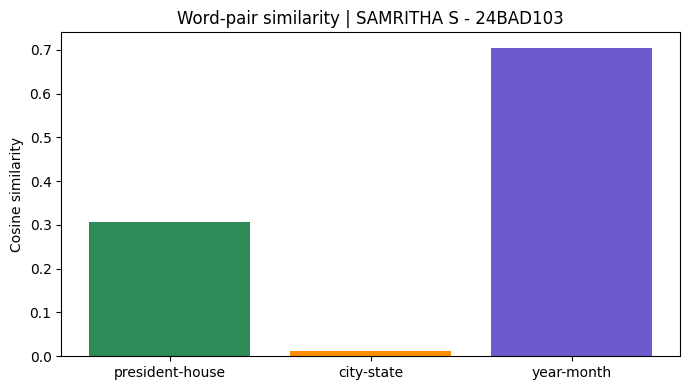

In [7]:
# Name: SAMRITHA S | Roll No: 24BAD103
print("Name: SAMRITHA S | Roll No: 24BAD103")
print("-" * 60)

vocab_in_model = w2v_model.wv.key_to_index

# Candidate meaningful pairs (only pairs present in the trained vocabulary are used)
candidate_pairs = [
    ("president", "house"), ("city", "state"), ("year", "month"),
    ("school", "student"), ("man", "woman"), ("government", "state"),
    ("people", "man"), ("new", "old"), ("time", "year"), ("county", "city"),
]
word_pairs = [p for p in candidate_pairs if p[0] in vocab_in_model and p[1] in vocab_in_model][:3]

# Fallback: if fewer than 3 pairs were found, pair up the most frequent words
top_words = w2v_model.wv.index_to_key[:10]
i = 0
while len(word_pairs) < 3:
    pair = (top_words[i], top_words[i + 1])
    if pair not in word_pairs:
        word_pairs.append(pair)
    i += 2

def cosine_sim(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

print(f"{'Word 1':<14}{'Word 2':<14}{'Gensim similarity':<20}{'NumPy cosine':<15}")
print("-" * 63)
results = []
for w1, w2 in word_pairs:
    g_sim = float(w2v_model.wv.similarity(w1, w2))
    n_sim = cosine_sim(w2v_model.wv[w1], w2v_model.wv[w2])
    results.append((w1, w2, g_sim))
    print(f"{w1:<14}{w2:<14}{g_sim:<20.4f}{n_sim:<15.4f}")

best = max(results, key=lambda r: r[2])
worst = min(results, key=lambda r: r[2])
print(f"\nMost similar pair  : ({best[0]}, {best[1]}) with cosine similarity = {best[2]:.4f}")
print(f"Least similar pair : ({worst[0]}, {worst[1]}) with cosine similarity = {worst[2]:.4f}")

# Bar chart comparing similarity scores
labels = [f"{a}-{b}" for a, b, _ in results]
scores = [s for _, _, s in results]
plt.figure(figsize=(7, 4))
plt.bar(labels, scores, color=["seagreen", "darkorange", "slateblue"])
plt.ylabel("Cosine similarity")
plt.title("Word-pair similarity | SAMRITHA S - 24BAD103")
plt.tight_layout()
plt.show()
